In [1]:
%load_ext autoreload
%autoreload 2
from mom6_bathy.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from pathlib import Path
from CrocoDash.case import Case

In [2]:
# CESM case (experiment) name
casename = "smoke.sink.bgc.cesm.1"

# CESM source root (Update this path accordingly!!!)
cesmroot ="/glade/u/home/manishrv/work/installs/CROCESM_workshop_2025"

# Place where all your input files go 
inputdir = Path.home()/"scratch" / "croc_input" / casename
    
# CESM case directory
caseroot = Path.home() / "croc_cases" / casename

bathymetry_path = "/glade/derecho/scratch/manishrv/croc_input/pan.drof.4/ocnice/ocean_topog_panama1_b27975.nc"
compset = "1850_DATM%NYF_SLND_SICE_MOM6%MARBL-BIO%REGIONAL_DROF%GLOFAS_SGLC_SWAV"

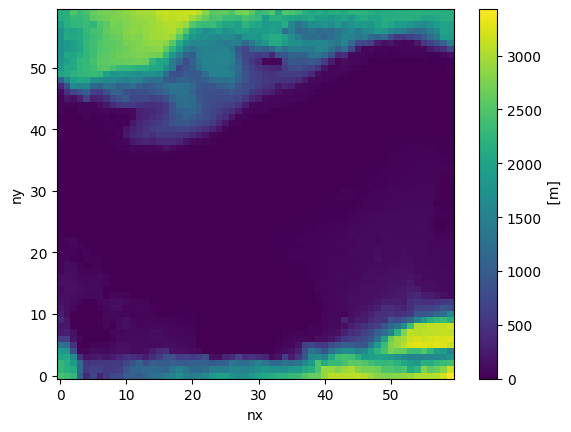

In [3]:
grid = Grid(
  resolution = 0.05, # in degrees
  xstart = 278.0, # min longitude in [0, 360]
  lenx = 3.0, # longitude extent in degrees
  ystart = 7.0, # min latitude in [-90, 90]
  leny = 3.0, # latitude extent in degrees
  name = "panama1",
)
topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 9.5,
)
topo.depth.plot()
vgrid  = VGrid.hyperbolic(
    nk = 75,
    depth = topo.max_depth,
    ratio=20.0
)

In [ ]:

case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'NCGD0011',
    override = True,
    machine = "derecho",
    compset = compset,
    atm_grid_name = "T62"
)

INFO:	initialize:Initializing the visualCaseGen system...


In [ ]:
case.configure_forcings(
    date_range = ["2000-01-01 00:00:00", "2000-02-01 00:00:00"],
    runoff_esmf_mesh_filepath = "/glade/campaign/cesm/cesmdata/cseg/inputdata/ocn/mom/croc/rof/glofas/dis24/GLOFAS_esmf_mesh_v4.nc",
    too_much_data = True,
    function_name = "get_mom6_data", # Path to CESM OUTPUT data
    product_name = "MOM6_OUTPUT",
    marbl_ic_filepath = "/glade/campaign/collections/gdex/data/d651077/cesmdata/inputdata/ocn/mom/tx0.66v1/ecosys_jan_IC_omip_latlon_1x1_180W_c231221.nc", # Path to MARBL Global IC File,
    global_river_nutrients_filepath = "/glade/campaign/cesm/cesmdata/cseg/inputdata/ocn/mom/croc/rof/river_nutrients/river_nutrients.GNEWS_GNM.glofas.20250916.64bit.nc",
    tidal_constituents = ['M2'],
    tpxo_elevation_filepath = "/glade/campaign/cgd/oce/projects/CROCODILE/workshops/2025/CrocoDash/data/tpxo/h_tpxo9.v1.nc",
    tpxo_velocity_filepath = "/glade/campaign/cgd/oce/projects/CROCODILE/workshops/2025/CrocoDash/data/tpxo/u_tpxo9.v1.nc",

)


INFO:CrocoDash.forcing_configurations:[OPTIONAL] Activating tides
INFO:CrocoDash.forcing_configurations:[REQUIRED] Activating BGC
INFO:CrocoDash.forcing_configurations:[SKIP] CICE incompatible with compset
INFO:CrocoDash.forcing_configurations:[REQUIRED] Activating BGCIC
INFO:CrocoDash.forcing_configurations:[REQUIRED] Activating BGCIronForcing
INFO:CrocoDash.forcing_configurations:[OPTIONAL] Activating BGCRiverNutrients
INFO:CrocoDash.forcing_configurations:[REQUIRED] Activating Runoff
INFO:CrocoDash.forcing_configurations:[SKIP] Chl incompatible with compset
INFO:CrocoDash.forcing_configurations:Configuring tides
INFO:CrocoDash.forcing_configurations:Configuring BGC
INFO:CrocoDash.forcing_configurations:Configuring BGCIC
INFO:CrocoDash.forcing_configurations:Configuring BGCIronForcing
INFO:CrocoDash.forcing_configurations:Configuring BGCRiverNutrients
INFO:CrocoDash.forcing_configurations:Configuring Runoff


Extract Forcings workflow was called, please go to the extract forcings path: /glade/u/home/manishrv/scratch/croc_input/smoke.sink.bgc.cesm.1/extract_forcings and run the driver script there.
Adding parameter changes to user_nl_mom:

  ! Enable tidal forcing in MOM6
  TIDES = True

Adding parameter changes to user_nl_mom:

  ! Enable M2 tidal constituent
  TIDE_M2 = True

Adding parameter changes to user_nl_mom:

  ! Drag coefficient for tidal forcing
  CD_TIDES = 0.0018

Adding parameter changes to user_nl_mom:

  ! Use equilibrium phase for tides
  TIDE_USE_EQ_PHASE = True

Adding parameter changes to user_nl_mom:

  ! Reference date for tidal forcing
  TIDE_REF_DATE = 2000, 01, 01

Adding parameter changes to user_nl_mom:

  ! Add equilibrium phase to OBC tides
  OBC_TIDE_ADD_EQ_PHASE = True

Adding parameter changes to user_nl_mom:

  ! Number of tidal constituents
  OBC_TIDE_N_CONSTITUENTS = 1

Adding parameter changes to user_nl_mom:

  ! List of tidal constituents
  OBC_TIDE_CON

In [18]:
# SAVED WAY
# Copy the shutil forcings
old_forcing_dir = Path("/glade/derecho/scratch/manishrv/croc_input/cesm.output.marbl.1/ocnice/")
# Copy all files starting with 'forcing_'
for file in old_forcing_dir.glob("*_obc_*"):
    if file.is_file():
        shutil.copy(file, case.inputdir/"ocnice" / file.name)
for file in old_forcing_dir.glob("*_IC*"):
    if file.is_file():
        shutil.copy(file, case.inputdir/"ocnice" / file.name)